# 06 · Trustworthy price ranges, bargains, and style twins

A point prediction ("€4.2M") is only half an answer. A club needs a **range it can trust**. This notebook:

1. Builds **conformal prediction intervals** around the blended model from 02 and *checks* that an "80% interval" really contains 80% of held-out players.
2. Shows **where the model is unsure** (by age and role) and fixes the intervals there with *Mondrian* (group-wise) conformal.
3. Uses the intervals as a **bargain finder**: players priced below the model's credible range.
4. Builds a **style-twin scout**: who plays like Haaland, De Bruyne or Van Dijk, and what they cost.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
d = pd.read_csv("../data/player_stats_clean.csv").merge(pd.read_csv("../data/roles.csv"), on=["player", "club", "age"])
d["pred"] = pd.read_csv("../data/oof_predictions.csv")["oof_blend"].values  # out-of-fold, from 02
d["resid"] = d.log_value - d.pred
d["age_band"] = pd.cut(d.age, [0, 21, 25, 29, 32, 35, 50], labels=["≤21", "22–25", "26–29", "30–32", "33–35", "36+"])
pd.options.display.float_format = "{:,.2f}".format

## 1. Split-conformal intervals, validated

Because every prediction is out-of-fold, its absolute log-residual is an honest sample of the model's error on unseen players. Conformal prediction takes the (1−α) quantile *q* of those errors and reports **[pred − q, pred + q]** on the log scale, i.e. **[price ÷ e^q, price × e^q]** in euros.

To *test* the procedure we calibrate *q* on 4 folds and measure coverage on the 5th.

In [2]:
def coverage_check(groups=None, alpha=0.2):
    cov, width = np.zeros(len(d), bool), np.zeros(len(d))
    for cal, te in KFold(5, shuffle=True, random_state=7).split(d):
        cal_r = d.resid.abs().iloc[cal]
        if groups is None:
            q = np.full(len(te), np.quantile(cal_r, 1 - alpha))
        else:
            qg = cal_r.groupby(d[groups].iloc[cal], observed=True).quantile(1 - alpha)
            q = d[groups].iloc[te].map(qg).astype(float).values
        cov[te] = d.resid.abs().iloc[te].values <= q
        width[te] = np.exp(q)
    return cov, width


out = {}
for name, g in [("global q", None), ("Mondrian by age band", "age_band")]:
    cov, w = coverage_check(g)
    out[name] = pd.DataFrame({"coverage": cov, "× factor": w}).groupby(d.age_band, observed=True).mean()
    out[name].loc["ALL"] = [cov.mean(), np.median(w)]
cmp = pd.concat(out, axis=1)
cmp.style.format({c: "{:.0%}" for c in cmp.columns if c[1] == "coverage"} | {c: "×{:.2f}" for c in cmp.columns if c[1] == "× factor"})

* With a single global *q*, the **80% interval** covers ~80% of players overall. Coverage is unequal, though: it over-covers the young and **under-covers players 33+**, whose prices are much harder to predict.
* **Mondrian conformal** (a separate *q* per age band) restores ~80% coverage in every band. Prime-age players get ranges of about ×1.25 either way, and players 36+ honestly wider ones (×1.7).

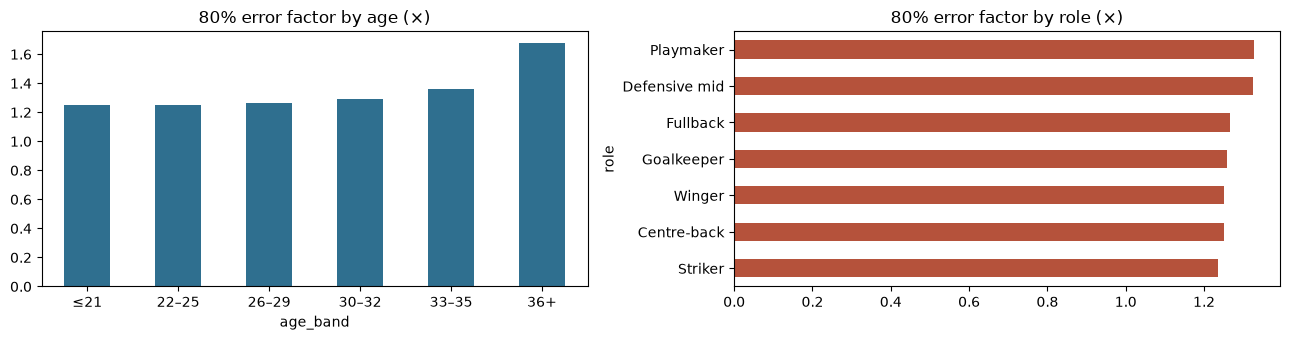

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
d.groupby("age_band", observed=True).resid.apply(lambda r: np.quantile(np.abs(r), .8)).pipe(np.exp).plot.bar(
    ax=ax[0], rot=0, color="#2f6f8f", title="80% error factor by age (×)")
d.groupby("role").resid.apply(lambda r: np.quantile(np.abs(r), .8)).pipe(np.exp).sort_values().plot.barh(
    ax=ax[1], color="#b5523b", title="80% error factor by role (×)")
plt.tight_layout()

## 2. Final intervals for every player
Mondrian *q* per age band, calibrated on all out-of-fold residuals.

In [4]:
ALPHA = 0.2
q = d.groupby("age_band", observed=True).resid.apply(lambda r: np.quantile(np.abs(r), 1 - ALPHA))
d["q"] = d.age_band.map(q).astype(float)
d["fair_m"] = np.exp(d.pred) / 1e6
d["lo_m"] = np.exp(d.pred - d.q) / 1e6
d["hi_m"] = np.exp(d.pred + d.q) / 1e6
d["price_vs_fair"] = d.value_m / d.fair_m

show = ["player", "club", "age", "role", "value_m", "fair_m", "lo_m", "hi_m"]
stars = ["Kylian Mbappé", "Erling Haaland", "Jude Bellingham", "Kevin De Bruyne", "Rodri", "Bukayo Saka", "Virgil van Dijk"]
d[d.player.isin(stars)][show].set_index("player")

,club,age,role,value_m,fair_m,lo_m,hi_m
player,,,,,,,
Bukayo Saka,Arsenal,21,Playmaker,47.50,48.12,38.55,60.08
Erling Haaland,Manchester City,23,Striker,123.00,87.16,69.78,108.86
Virgil van Dijk,Liverpool,32,Centre-back,84.50,52.38,40.48,67.78
Kevin De Bruyne,Manchester City,32,Playmaker,107.50,110.88,85.69,143.46
Kylian Mbappé,Paris SG,24,Striker,153.50,202.71,162.29,253.18
Rodri,Manchester City,27,Defensive mid,77.00,46.27,36.52,58.60


## 3. Bargain finder
Players whose actual FIFA price sits **below the lower edge** of their 80% range: the game prices them cheaper than their attributes and age imply. With an 80% interval, ~10% of players fall below by chance, so we rank by how far below they are and focus on players under 27 with real quality (reactions ≥ 70).

*Reading this correctly:* in FIFA 24 these are cards where the hidden overall/potential ratings sit lower than the visible attributes suggest. That makes them the best **value-for-attributes** buys in Career Mode.

In [5]:
below = d[(d.value_m < d.lo_m)]
print(f"{len(below)} players ({len(below) / len(d):.1%}) below their 80% range (≈10% expected by chance)")
bargains = d[(d.value_m < d.lo_m) & (d.age <= 26) & (d.reactions >= 70)].sort_values("price_vs_fair")
bargains[show + ["reactions", "price_vs_fair"]].head(15).style.format(
    {"value_m": "€{:.1f}M", "fair_m": "€{:.1f}M", "lo_m": "€{:.1f}M", "hi_m": "€{:.1f}M", "price_vs_fair": "{:.0%} of fair"}).hide(axis="index")

595 players (10.5%) below their 80% range (≈10% expected by chance)


player,club,age,role,value_m,fair_m,lo_m,hi_m,reactions,price_vs_fair
Dennis Geiger,TSG Hoffenheim,25,Defensive mid,€6.0M,€13.3M,€10.6M,€16.6M,79,45% of fair
Danylo Ignatenko,Bordeaux,26,Defensive mid,€1.8M,€3.4M,€2.7M,€4.3M,72,53% of fair
Jules Van Cleemput,Sp. Charleroi,26,Fullback,€1.5M,€2.8M,€2.2M,€3.5M,71,54% of fair
Valentín Gómez,Vélez Sarsfield,20,Centre-back,€1.5M,€2.8M,€2.2M,€3.5M,70,54% of fair
Carlos Augusto,Monza,24,Defensive mid,€3.5M,€6.3M,€5.1M,€7.9M,72,55% of fair
Tomás Belmonte,Lanús,25,Defensive mid,€2.7M,€4.7M,€3.8M,€5.9M,71,57% of fair
Francisco Vidangosa,Ind. Petrolero,23,Goalkeeper,€0.8M,€1.3M,€1.0M,€1.6M,75,58% of fair
Dani de Wit,AZ,25,Defensive mid,€6.5M,€11.2M,€9.0M,€14.0M,79,58% of fair
David Tavares,FC Famalicão,24,Defensive mid,€0.8M,€1.4M,€1.1M,€1.8M,70,59% of fair
António Silva,SL Benfica,19,Centre-back,€5.0M,€8.3M,€6.7M,€10.4M,78,60% of fair


And the other side: the most **over-priced** cards relative to their attributes.

In [6]:
d[d.value_m > d.hi_m].sort_values("price_vs_fair", ascending=False)[show + ["price_vs_fair"]].head(10).style.format(
    {"value_m": "€{:.1f}M", "fair_m": "€{:.1f}M", "lo_m": "€{:.1f}M", "hi_m": "€{:.1f}M", "price_vs_fair": "{:.1f}× fair"}).hide(axis="index")

player,club,age,role,value_m,fair_m,lo_m,hi_m,price_vs_fair
Neto,AFC Bournemouth,34,Goalkeeper,€10.5M,€3.7M,€2.7M,€5.1M,2.8× fair
Samir Ujkani,Empoli,35,Goalkeeper,€0.4M,€0.2M,€0.1M,€0.2M,2.6× fair
Rodrigo Vuarte,Atlético Mineiro,31,Defensive mid,€9.0M,€3.6M,€2.8M,€4.6M,2.5× fair
Jason Bardeira,Brazil,23,Striker,€17.0M,€6.8M,€5.5M,€8.5M,2.5× fair
Luuk de Jong,PSV,33,Striker,€15.0M,€6.3M,€4.6M,€8.6M,2.4× fair
Federico Bernardeschi,Toronto FC,29,Playmaker,€17.5M,€7.7M,€6.1M,€9.8M,2.3× fair
James Ward-Prowse,Southampton,28,Defensive mid,€27.5M,€13.2M,€10.4M,€16.7M,2.1× fair
Igor,Fiorentina,25,Centre-back,€7.5M,€3.6M,€2.9M,€4.5M,2.1× fair
Pietro Beruatto,Pisa,24,Fullback,€6.0M,€3.0M,€2.4M,€3.7M,2.0× fair
Florian Neuhaus,M'gladbach,26,Defensive mid,€19.5M,€9.7M,€7.7M,€12.3M,2.0× fair


Over-priced cards are dominated by **goalkeepers and veterans**, the two groups the model finds hardest (section 1). Their rows are where the hidden overall rating diverges most from the visible attributes.

## 4. Style-twin scout: "plays like X, costs a fraction"

Two players have the same **style** if their attribute *profiles* match after removing overall level (the same centring used for role discovery in 03). Rank candidates by style similarity (cosine), keep those within 10 reactions points of the target, and show what each would cost.

In [7]:
OUTF = list(d.loc[:, "ball_control":"volleys"].columns)  # the 28 outfield attributes
centred = d[OUTF].sub(d[OUTF].mean(axis=1), axis=0)
Z = StandardScaler().fit_transform(centred)
Z /= np.linalg.norm(Z, axis=1, keepdims=True)


def style_twins(name, n=8, max_gap=10):
    i = d.index[d.player == name][0]
    sim = Z @ Z[i]
    cand = d.assign(style_similarity=sim)
    cand = cand[(cand.index != i) & (cand.is_gk == d.is_gk[i]) & (cand.reactions >= d.reactions[i] - max_gap)]
    out = cand.nlargest(n, "style_similarity")[["player", "club", "age", "reactions", "value_m", "style_similarity"]]
    out["cost vs target"] = out.value_m / d.value_m[i]
    print(f"\n{name}: {d.club[i]}, age {d.age[i]}, reactions {d.reactions[i]}, €{d.value_m[i]}M")
    return out.style.format({"value_m": "€{:.1f}M", "style_similarity": "{:.2f}", "cost vs target": "{:.0%}"}).hide(axis="index")


for star in ["Erling Haaland", "Kevin De Bruyne", "Virgil van Dijk"]:
    display(style_twins(star))


Erling Haaland: Manchester City, age 23, reactions 89, €123.0M


player,club,age,reactions,value_m,style_similarity,cost vs target
Moussa Dembélé,OL,27,80,€20.0M,0.84,16%
Aleksandar Mitrović,Fulham,28,79,€19.0M,0.84,15%
Simon Terodde,FC Schalke 04,35,79,€2.7M,0.80,2%
Tammy Abraham,Roma,25,84,€35.5M,0.80,29%
Callum Wilson,Newcastle Utd,31,81,€20.5M,0.79,17%
Valentin Castellanos,Girona FC,24,79,€12.5M,0.76,10%
Jamie Vardy,Leicester City,36,84,€13.0M,0.76,11%
Lautaro Martínez,Inter,26,89,€79.5M,0.75,65%



Kevin De Bruyne: Manchester City, age 32, reactions 91, €107.5M


player,club,age,reactions,value_m,style_similarity,cost vs target
Mason Mount,Chelsea,24,85,€42.0M,0.94,39%
Jonas Hofmann,M'gladbach,31,83,€25.5M,0.91,24%
Bruno Fernandes,Manchester Utd,28,91,€72.5M,0.90,67%
Marco Reus,Borussia Dortmund,34,86,€33.5M,0.87,31%
Emil Forsberg,RB Leipzig,31,83,€20.5M,0.86,19%
João Mário,SL Benfica,30,81,€25.5M,0.86,24%
Ignacio Fernández,River Plate,33,81,€16.5M,0.85,15%
Canales,Real Betis,32,84,€35.0M,0.83,33%



Virgil van Dijk: Liverpool, age 32, reactions 89, €84.5M


player,club,age,reactions,value_m,style_similarity,cost vs target
Raphaël Varane,Manchester Utd,30,85,€45.0M,0.83,53%
Rafael Tolói,Bergamo Calcio,32,83,€17.5M,0.82,21%
Nayef Aguerd,West Ham,27,80,€20.0M,0.82,24%
Kalidou Koulibaly,Chelsea,32,83,€46.5M,0.82,55%
Leonardo Bonucci,Juventus,36,80,€8.0M,0.79,9%
Gabriel,Arsenal,25,81,€30.5M,0.77,36%
Filipe Relvas,Portimonense SC,23,79,€2.4M,0.74,3%
Iñigo Martínez Berridi,Athletic Club,32,81,€21.0M,0.71,25%


### Value-for-money frontier
Each dot is a player. Reading up the y-axis is more ability, reading left on the x-axis is cheaper. Players on the upper-left edge give the most ability per euro at their age.

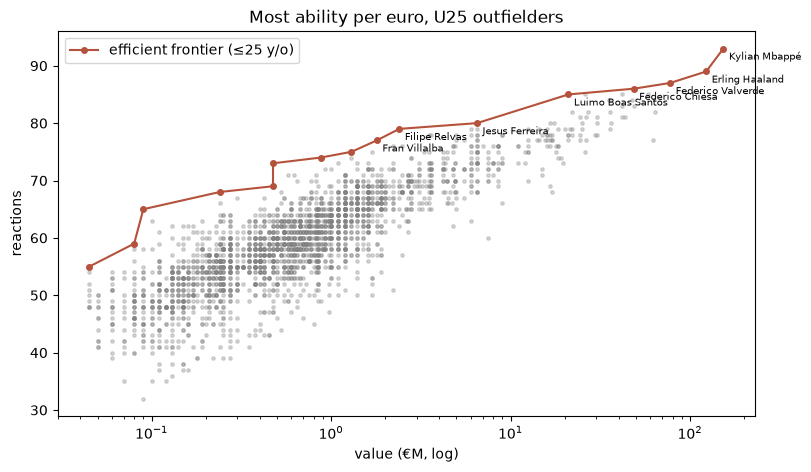

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
s = d[(d.is_gk == 0) & (d.age <= 25)]
ax.scatter(s.value_m, s.reactions, s=6, alpha=0.3, color="grey")
frontier = s.sort_values("value_m").assign(best=lambda t: t.reactions.cummax())
frontier = frontier[frontier.reactions == frontier.best].drop_duplicates("best")
ax.plot(frontier.value_m, frontier.reactions, "o-", color="#b5523b", ms=4, label="efficient frontier (≤25 y/o)")
for _, r in frontier.tail(8).iterrows():
    ax.annotate(r.player, (r.value_m, r.reactions), fontsize=7, xytext=(4, -8), textcoords="offset points")
ax.set(xscale="log", xlabel="value (€M, log)", ylabel="reactions", title="Most ability per euro, U25 outfielders")
ax.legend();

## Takeaways
* **Calibrated uncertainty.** "80% range" means 80% across the board after Mondrian calibration. For a typical prime-age player the range is price ÷1.25 to ×1.25; for a 36-year-old it is ÷1.7 to ×1.7, and the model says so.
* **The model is a pricing lens.** Residuals become a bargain list, and profile vectors become a scouting tool. Both come from the same validated model.
* **Scope reminder:** all of this explains *FIFA 24's* pricing formula. Pointing it at real transfer fees would need real market data (contracts, league, performance).